# Exercise 6 - Solution
***

> **Aim:** To use a Monte Carlo method to propagate error through a calculation.

As a reminder, the equations we are trying to use:

\begin{align}
T(\mathrm{K}) = \frac{10^4}{0.575 + 0.884\,Y_\mathrm{Cr} - 0.897\ln(\mathrm{k_d})},
\end{align}

where the coefficients are 0.575 ± 0.162, 0.884 ± 0.043 and 0.897 ± 0.025 (1 sigma),

\begin{align}
Y_\mathrm{Cr} = \frac{X_\mathrm{Cr}}{(X_\mathrm{Cr}+X_\mathrm{Al})},
\end{align}

\begin{align}
X_i = \frac{w_i/m_i}{\sum{w_j/m_j}},
\end{align}

\begin{align}
\mathrm{k_d} = \frac{\mathsf{Al_2O_3^{olivine}}}{\mathsf{Al_2O_3^{spinel}}},
\end{align}

|molecule| mean molecular mass |
|-----------|------------|
|SiO$_2$    | 60.0 |
|MgO        | 40.3 |
|AlO$_{1.5}$| 51.0 |
|TiO$_2$    | 79.9 |
|CaO        | 56.0 |
|FeO        | 71.8 |
|CrO$_{1.5}$| 76.0 |
|MnO        | 70.9 |
|NiO        | 74.7 |

All the hard work with this exercise is in manipulating the data.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
#read in the data, which are in the exercises folder
df = pd.read_excel('../exercises/data/crystal_ts.xlsx', index_col=None, header=0)
#the molecular weights file has no header and is separated by spaces. index_col=0 uses the oxide names
# as the row names, and .squeeze() turns the single column into a Series, so mw['alo'] gives 51.0
mw = pd.read_csv('../exercises/data/molecular_weights.txt', sep=' ', index_col=0, header=None).squeeze()
df

,Location,Sample,sio2,sio2_1sig,mgo,mgo_1sig,al2o3,al2o3_1sig,tio2,tio2_1sig,cao,cao_1sig,feo,feo_1sig,cr2o3,cr2o3_1sig,mno,mno_1sig,nio,nio_1sig
0,Hawaii,olivine,40.94770,2.866339,47.598800,3.331916,0.049200,0.003444,0.261150,0.018281,11.24145,0.786902,0.107100,0.007497,NaN,NaN,0.15985,0.011189,0.413700,0.028959
1,Hawaii,spinel,0.11910,0.008337,13.379233,0.936546,14.047633,0.983334,1.723467,0.120643,NaN,NaN,21.915167,1.534062,46.478867,3.253521,0.20150,0.014105,0.243033,0.017012
2,Iceland,olivine,40.85429,2.859800,47.811850,3.346830,0.083720,0.005860,NaN,NaN,0.41181,0.028827,9.920710,0.694450,NaN,NaN,NaN,NaN,0.297990,0.020859
3,Iceland,spinel,NaN,NaN,18.938300,1.325681,43.656700,3.055969,NaN,NaN,NaN,NaN,13.470400,0.942928,21.388600,1.497202,NaN,NaN,NaN,NaN


In [3]:
#the two files have different names for the oxides, reflecting whether, e.g., Al2O3 or AlO1.5 is being talked about.
# We deal with this by making two lists in the same order, so the n'th entry of one matches the n'th entry of the other
#oxide weight percents in the data file...
wvec = ['sio2', 'mgo', 'al2o3', 'tio2', 'cao', 'feo', 'cr2o3', 'mno', 'nio']
#...the names of their error columns, which we make from the previous list using a list comprehension...
wvece = [w + '_1sig' for w in wvec]
#...and the matching single-cation names in the molecular weights file
mvec = ['sio', 'mgo', 'alo', 'tio', 'cao', 'feo', 'cro', 'mno', 'nio']
#the molecular weights in the same order as wvec, as a numpy array
m = mw[mvec].to_numpy()

#we will need to find the positions of Al and Cr in these lists
iAl = wvec.index('al2o3')
iCr = wvec.index('cr2o3')

#coefficients for the temperature calculation from Coogan et al. 2014, and their 1 sigma errors
coeffs = np.array([0.575, 0.884, 0.897])
coeffse = np.array([0.162, 0.043, 0.025])

#number of iterations to perform for Monte Carlo error propagation
Ndraw = 10000

def composition(location, sample):
    """Return the weight percents and their 1 sigma errors for one sample, as numpy arrays."""
    row = df[(df.Location == location) & (df.Sample == sample)]
    return row[wvec].to_numpy()[0], row[wvece].to_numpy()[0]

def temperatures(location):
    """Return Ndraw temperatures (K) for one location, perturbing everything by its error each time."""
    ol, ol_e = composition(location, 'olivine')
    sp, sp_e = composition(location, 'spinel')

    #rather than looping Ndraw times, we draw all the random perturbations at once: each row is one
    # draw, and each column one oxide. numpy repeats the 1D arrays of means and errors for every row.
    # missing values (NaN) stay as NaN
    ol_p = np.random.normal(ol, ol_e, size=(Ndraw, len(ol)))
    sp_p = np.random.normal(sp, sp_e, size=(Ndraw, len(sp)))

    #atomic (cation) fractions in the spinel for every draw: divide by the molecular masses, then
    # renormalise each row. np.nansum(..., axis=1, keepdims=True) sums along each row, ignoring the NaNs
    # (i.e., treating missing oxides as zero)
    cations = sp_p / m
    X = cations / np.nansum(cations, axis=1, keepdims=True)
    Y = X[:, iCr] / (X[:, iCr] + X[:, iAl])

    #the exchange coefficient uses the weight percents directly
    kd = ol_p[:, iAl] / sp_p[:, iAl]

    #perturb the coefficients of the thermometer too: one row of three coefficients per draw
    c = np.random.normal(coeffs, coeffse, size=(Ndraw, 3))

    return 1e4 / (c[:, 0] + c[:, 1]*Y - c[:, 2]*np.log(kd))

T_ice = temperatures('Iceland')
T_haw = temperatures('Hawaii')

#the thermometer gives temperatures in kelvin
print(f'Iceland: {np.mean(T_ice):.0f} +/- {np.std(T_ice):.0f} K ({np.mean(T_ice)-273.15:.0f} degrees C)')
print(f'Hawaii:  {np.mean(T_haw):.0f} +/- {np.std(T_haw):.0f} K ({np.mean(T_haw)-273.15:.0f} degrees C)')

Iceland: 1563 +/- 59 K (1290 degrees C)
Hawaii:  1602 +/- 60 K (1329 degrees C)


Do the two settings record different temperatures? Let's look at the two distributions.

Hawaii is hotter in 68% of the paired draws


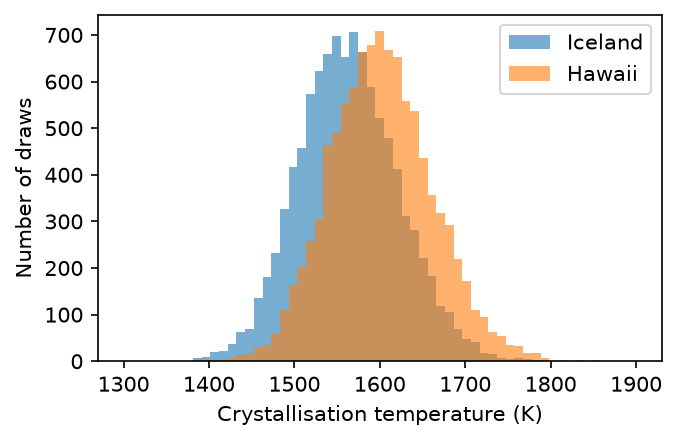

In [4]:
fig, ax = plt.subplots(1)
bins = np.linspace(1300, 1900, 60)
ax.hist(T_ice, bins=bins, alpha=0.6, label='Iceland')
ax.hist(T_haw, bins=bins, alpha=0.6, label='Hawaii')
ax.set_xlabel('Crystallisation temperature (K)')
ax.set_ylabel('Number of draws')
ax.legend();

#save the figure to a file
fig.savefig('exercise6_temperatures.png', dpi=300, bbox_inches='tight')

#how often is the Hawaii temperature higher than the Iceland one, if we pair up the random draws?
print(f'Hawaii is hotter in {np.mean(T_haw > T_ice)*100:.0f}% of the paired draws')

Most of the uncertainty comes from the coefficients of the thermometer itself (about $\pm$55 K, compared with about $\pm$20 K from the compositions), and these are shared by both samples. So comparing the two distributions above, which treat the coefficient errors as independent for each sample, overstates how hard it is to tell them apart. A fairer comparison would use the same perturbed coefficients for both samples in each draw. Try it! (When we did, Hawaii came out hotter in about 90% of the draws, by 37 $\pm$ 30 K.)

## Your turn answers
***

Model answers to the **Your turn** and **Fix the bug** tasks in `Exercise6.ipynb`, in the order they appear.  They use variables from earlier in that notebook, so they are shown here as code to read rather than to run.

### Reproducing random numbers with a seed

```python
rand.seed(42)
rolls = [rand.randint(1, 6) for i in range(5)]
check('seed rolls', rolls)
```

### Drawing from a normal distribution

```python
draws = np.random.normal(5, 2, 10000)
draws_mean = np.mean(draws)
draws_std = np.std(draws)
check('normal mean', draws_mean)
check('normal std', draws_std)
```

### Fix the bug: rolling a die

```python
rolls = np.random.randint(1, 7, 100000)
check('die', np.mean(rolls))
```

### Two dice

```python
die1 = np.random.randint(1, 7, 100000)
die2 = np.random.randint(1, 7, 100000)
p_seven = np.mean(die1 + die2 == 7)
check('seven', p_seven)
```

### Switching boxes (the faded example)

```python
#now let's look at switching
# remembering to reset our win counter
win_count = 0
for i in range(0,Ngames):
    #shuffle the boxes
    rand.shuffle(box)

    #pick our box
    pick = rand.choice([0, 1, 2])

    #now the host needs to pick their box, and they will always pick an empty box
    for j, b in enumerate(box):
        if j != pick and b == 'sadness':
            show = j

    #this time we switch to the remaining box: the one that is neither our pick nor the one the host showed us.
    # the three indices add up to 0 + 1 + 2 = 3, so the remaining one is 3 - pick - show
    remaining = 3 - pick - show

    if box[remaining] == 'shapp':
        win_count = win_count + 1

print(f'Switching, we won {win_count/Ngames*100:.1f} percent of the time')
check('switch', win_count/Ngames)
```